# Credit Card Fraud Detection

The goal is to detect fraudulent credit card transactions. The dataset is very imbalanced (only 0.17% of frauds), so I don't use accuracy to compare the models.

At the end I also compute how much money each model would make the bank lose.

# Import Libraries

In [125]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import average_precision_score, precision_recall_curve

import warnings
warnings.filterwarnings('ignore')

# Load Data

In [126]:
df = pd.read_csv('data/creditcard.csv')

In [127]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [128]:
df.shape

(284807, 31)

In [129]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [130]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [131]:
df.isna().sum().sum()

np.int64(0)

# Duplicates

In [132]:
df.duplicated().sum()

np.int64(1081)

In [133]:
df = df.drop_duplicates()
df.shape

(283726, 31)

# EDA

## Class Distribution

In [134]:
df['Class'].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

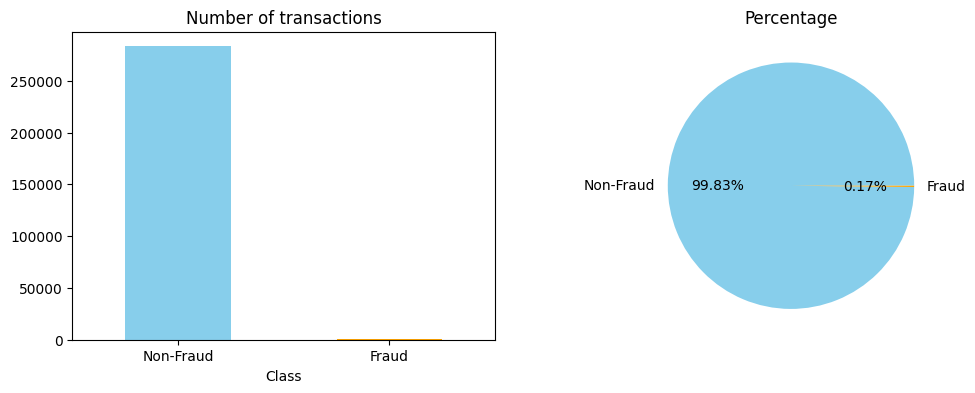

In [135]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['Class'].value_counts().plot(kind='bar', color=['skyblue', 'orange'], ax=axes[0])
axes[0].set_xticklabels(['Non-Fraud', 'Fraud'], rotation=0)
axes[0].set_title('Number of transactions')

df['Class'].value_counts().plot(kind='pie', labels=['Non-Fraud', 'Fraud'], autopct='%1.2f%%',
                                colors=['skyblue', 'orange'], ax=axes[1])
axes[1].set_ylabel('')
axes[1].set_title('Percentage')
plt.show()

Only 0.17% of the transactions are frauds.

## Amount

In [136]:
fraud = df[df['Class'] == 1]
normal = df[df['Class'] == 0]

In [137]:
fraud['Amount'].describe()

count     473.000000
mean      123.871860
std       260.211041
min         0.000000
25%         1.000000
50%         9.820000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64

In [138]:
normal['Amount'].describe()

count    283253.000000
mean         88.413575
std         250.379023
min           0.000000
25%           5.670000
50%          22.000000
75%          77.460000
max       25691.160000
Name: Amount, dtype: float64

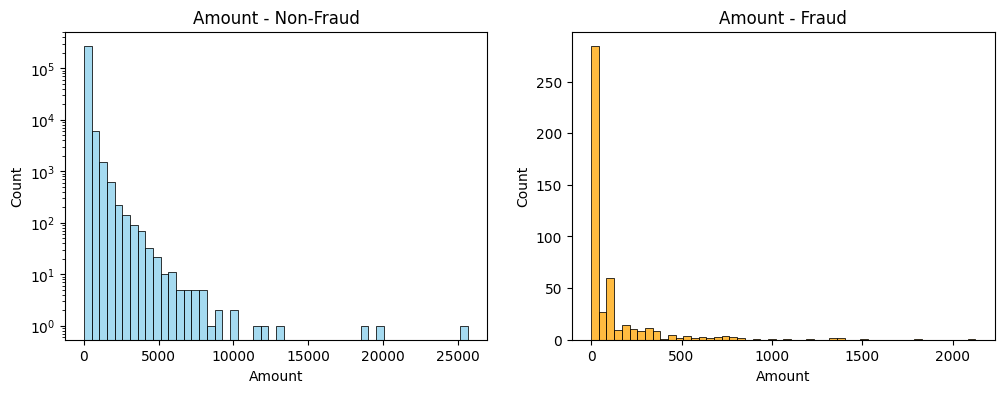

In [139]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(normal['Amount'], bins=50, color='skyblue', ax=axes[0])
axes[0].set_title('Amount - Non-Fraud')
axes[0].set_yscale('log')
sns.histplot(fraud['Amount'], bins=50, color='orange', ax=axes[1])
axes[1].set_title('Amount - Fraud')
plt.show()

Most frauds are small amounts (median around 9 €), and no fraud is above about 2 126 €.

## Time

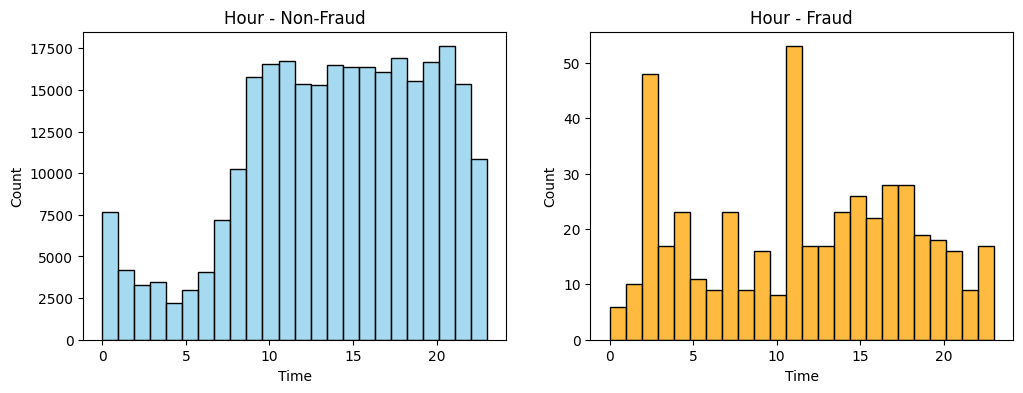

In [140]:
df['Hour'] = (df['Time'] // 3600) % 24

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(normal['Time'] // 3600 % 24, bins=24, color='skyblue', ax=axes[0])
axes[0].set_title('Hour - Non-Fraud')
sns.histplot(fraud['Time'] // 3600 % 24, bins=24, color='orange', ax=axes[1])
axes[1].set_title('Hour - Fraud')
plt.show()

Normal transactions are rare at night, but frauds still happen at night, so the fraud rate is higher during the night.

In [141]:
df = df.drop(columns='Hour')

## Correlation

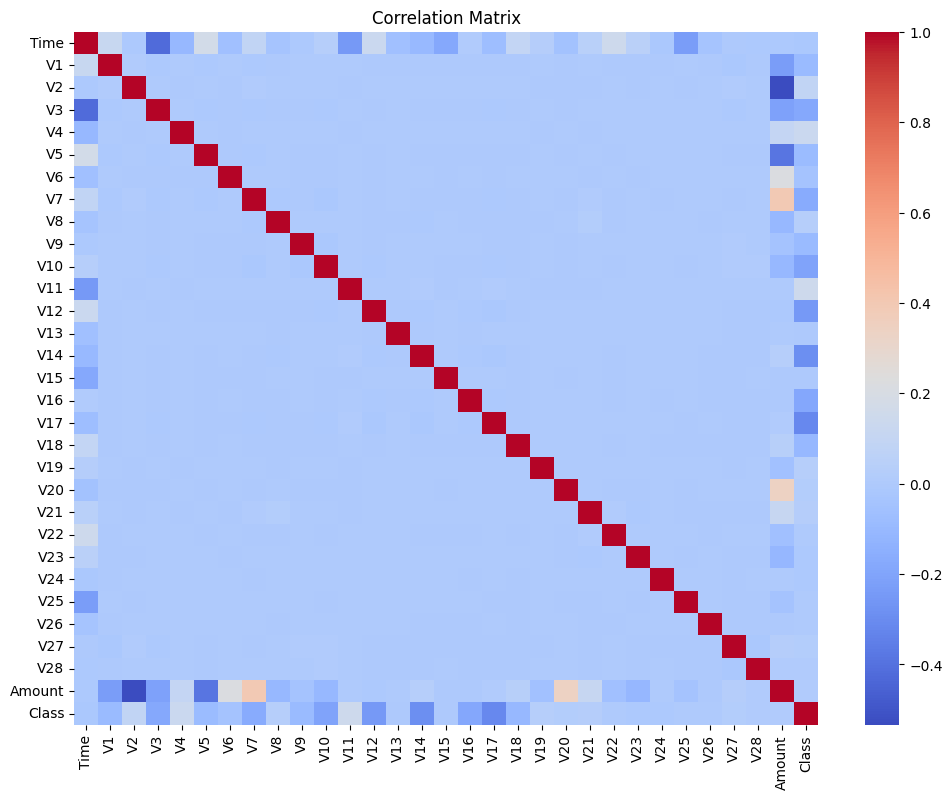

In [142]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

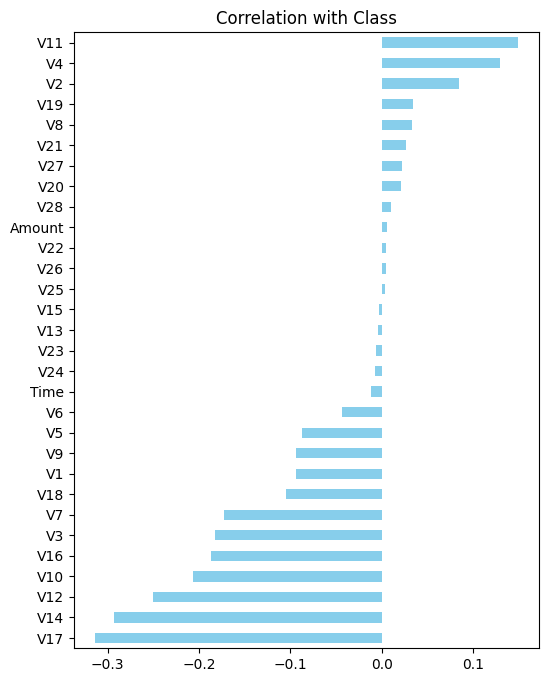

In [143]:
corr = df.corr()['Class'].drop('Class').sort_values()

plt.figure(figsize=(6, 8))
corr.plot(kind='barh', color='skyblue')
plt.title('Correlation with Class')
plt.show()

V1 to V28 are not correlated with each other (they come from a PCA). V14, V17, V12 and V10 are the most correlated with fraud.

## Boxplots

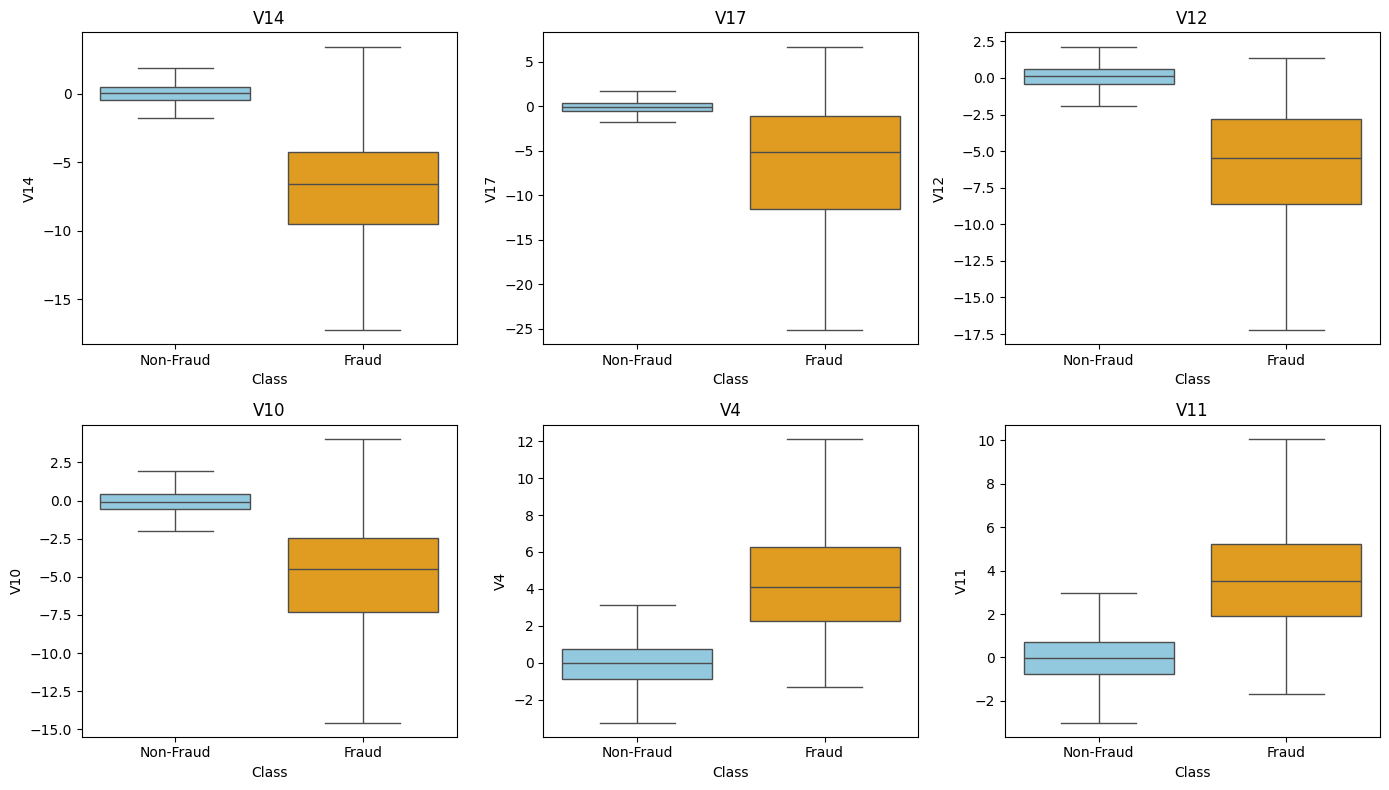

In [144]:
features = ['V14', 'V17', 'V12', 'V10', 'V4', 'V11']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, feature in zip(axes.flatten(), features):
    sns.boxplot(x='Class', y=feature, data=df, palette=['skyblue', 'orange'], showfliers=False, ax=ax)
    ax.set_xticklabels(['Non-Fraud', 'Fraud'])
    ax.set_title(feature)
plt.tight_layout()
plt.show()

For these features, frauds have very different values than normal transactions. The models should use them a lot.

# Preprocessing

In [145]:
X = df.drop(columns='Class')
y = df['Class']

In [146]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print('Train:', X_train.shape, '- frauds:', y_train.sum())
print('Test: ', X_test.shape, '- frauds:', y_test.sum())

Train: (226980, 30) - frauds: 378
Test:  (56746, 30) - frauds: 95


`stratify=y` keeps the same percentage of frauds in train and test. Then I scale `Time` and `Amount` (V1-V28 are already scaled). The scaler is fitted on the train set only.

In [147]:
amount_test = X_test['Amount'].values   # real amounts, used later for the cost

scaler = StandardScaler()
X_train[['Time', 'Amount']] = scaler.fit_transform(X_train[['Time', 'Amount']])
X_test[['Time', 'Amount']] = scaler.transform(X_test[['Time', 'Amount']])

# Why accuracy is not a good metric

In [148]:
y_pred_naive = np.zeros(len(y_test))   # always predict Non-Fraud

print('Accuracy:', accuracy_score(y_test, y_pred_naive))
print('Recall:  ', recall_score(y_test, y_pred_naive))

Accuracy: 0.9983258731892997
Recall:   0.0


Predicting always Non-Fraud gives 99.8% accuracy but 0 fraud detected. I will use precision, recall, F1 and PR-AUC instead.

# Models

In [149]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4, n_jobs=-1, random_state=42),
    'LightGBM': LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, n_jobs=-1,
                               random_state=42, verbose=-1),
}

In [150]:
predictions = {}
probas = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    probas[name] = model.predict_proba(X_test)[:, 1]
    print(name, 'done')

Logistic Regression done
Decision Tree done
Random Forest done
XGBoost done
LightGBM done


## Classification Reports

In [151]:
for name in models:
    print('=====', name, '=====')
    print(classification_report(y_test, predictions[name], digits=3))

===== Logistic Regression =====
              precision    recall  f1-score   support

           0      0.999     1.000     1.000     56651
           1      0.848     0.589     0.696        95

    accuracy                          0.999     56746
   macro avg      0.924     0.795     0.848     56746
weighted avg      0.999     0.999     0.999     56746

===== Decision Tree =====
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     56651
           1      0.883     0.716     0.791        95

    accuracy                          0.999     56746
   macro avg      0.941     0.858     0.895     56746
weighted avg      0.999     0.999     0.999     56746

===== Random Forest =====
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     56651
           1      0.972     0.726     0.831        95

    accuracy                          1.000     56746
   macro avg      0.986     0.863     0.916 

## Confusion Matrices

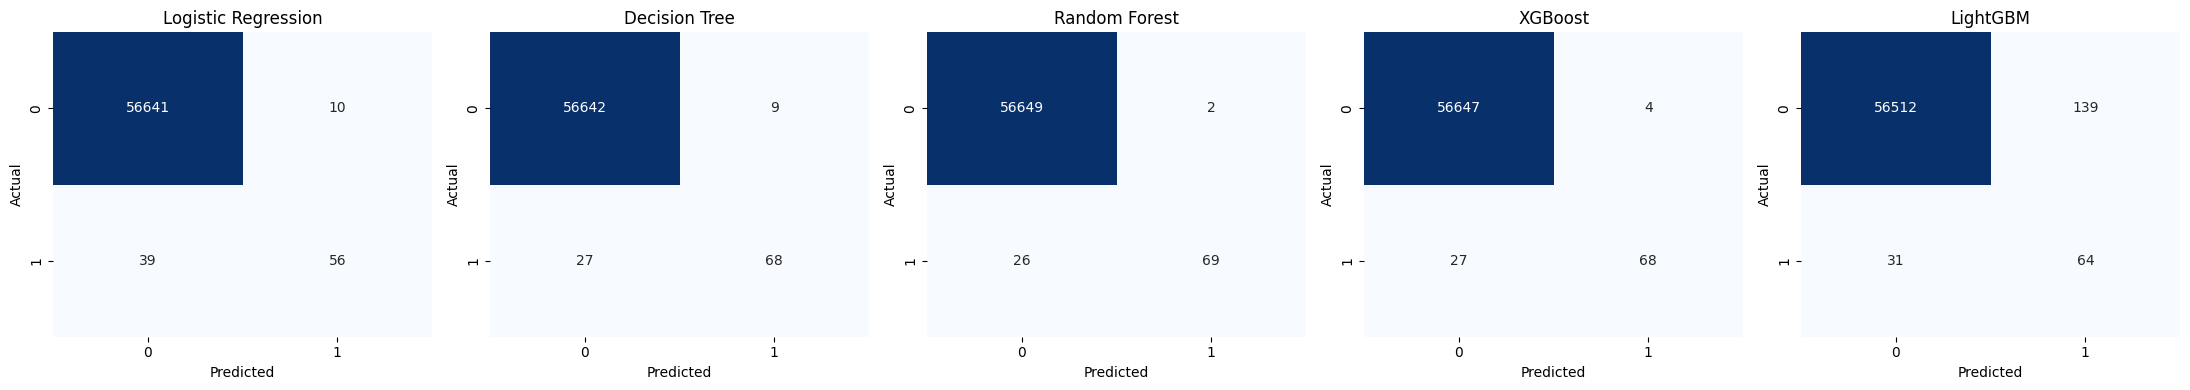

In [152]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, name in zip(axes, models):
    sns.heatmap(confusion_matrix(y_test, predictions[name]), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

## Logistic Regression on one feature

To show how logistic regression works, I train it only on V14. Frauds are at the top (1), normal transactions at the bottom (0), and the red line is the probability of fraud.

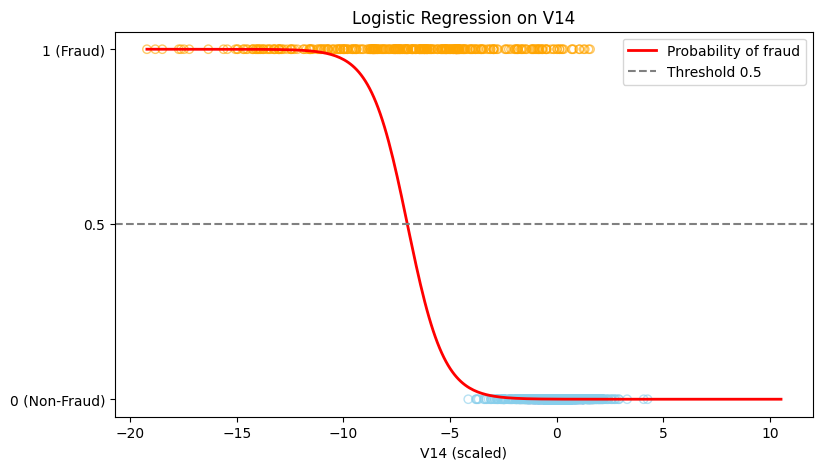

In [153]:
log_v14 = LogisticRegression()
log_v14.fit(X_train[['V14']], y_train)

sample = pd.concat([X_train[y_train == 1], X_train[y_train == 0].sample(2000, random_state=42)])
y_sample = y_train.loc[sample.index]

x_line = np.linspace(X_train['V14'].min(), X_train['V14'].max(), 300)
y_line = log_v14.predict_proba(pd.DataFrame({'V14': x_line}))[:, 1]

plt.figure(figsize=(9, 5))
plt.scatter(sample['V14'], y_sample, facecolors='none',
            edgecolors=np.where(y_sample == 1, 'orange', 'skyblue'), alpha=0.6)
plt.plot(x_line, y_line, color='red', linewidth=2, label='Probability of fraud')
plt.axhline(0.5, color='gray', linestyle='--', label='Threshold 0.5')
plt.yticks([0, 0.5, 1], ['0 (Non-Fraud)', '0.5', '1 (Fraud)'])
plt.xlabel('V14 (scaled)')
plt.title('Logistic Regression on V14')
plt.legend()
plt.show()

# Model Comparison

In [154]:
results = []
for name in models:
    results.append([name,
                    accuracy_score(y_test, predictions[name]),
                    precision_score(y_test, predictions[name]),
                    recall_score(y_test, predictions[name]),
                    f1_score(y_test, predictions[name]),
                    average_precision_score(y_test, probas[name])])

results = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'PR-AUC'])
results = results.set_index('Model').round(3)
results.sort_values('PR-AUC', ascending=False)

,Accuracy,Precision,Recall,F1,PR-AUC
Model,,,,,
XGBoost,0.999,0.944,0.716,0.814,0.809
Random Forest,1.000,0.972,0.726,0.831,0.788
Logistic Regression,0.999,0.848,0.589,0.696,0.692
Decision Tree,0.999,0.883,0.716,0.791,0.629
LightGBM,0.997,0.315,0.674,0.430,0.498


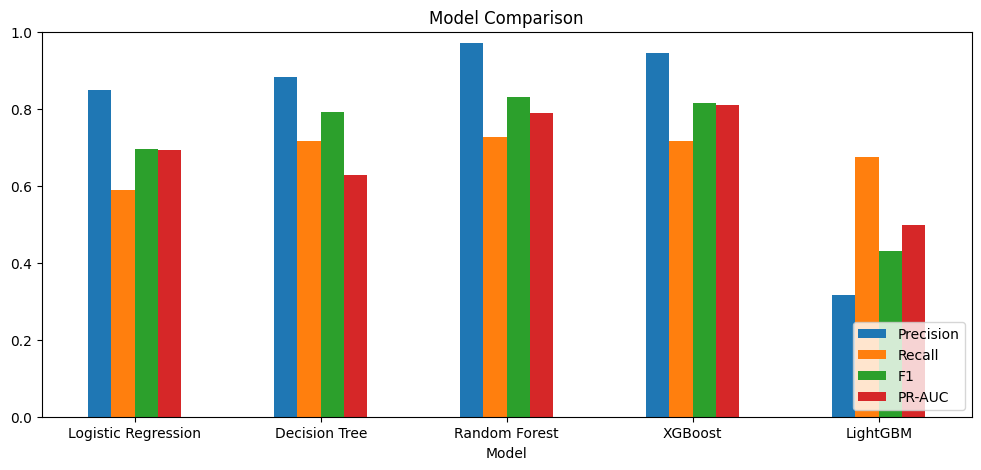

In [155]:
results[['Precision', 'Recall', 'F1', 'PR-AUC']].plot(kind='bar', figsize=(12, 5), rot=0)
plt.ylim(0, 1)
plt.title('Model Comparison')
plt.legend(loc='lower right')
plt.show()

Accuracy is almost the same for all models (around 99.9%), that's why I compare them with precision, recall, F1 and PR-AUC.

## Precision-Recall Curves

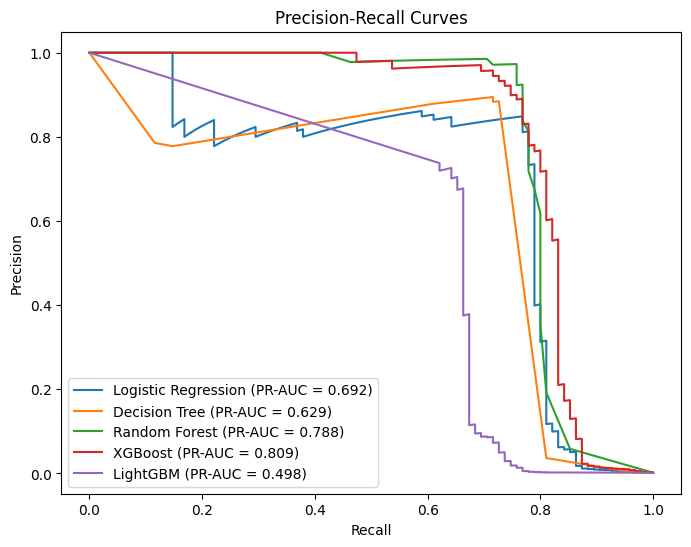

In [156]:
plt.figure(figsize=(8, 6))
for name in models:
    precision, recall, _ = precision_recall_curve(y_test, probas[name])
    plt.plot(recall, precision, label=f"{name} (PR-AUC = {average_precision_score(y_test, probas[name]):.3f})")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves')
plt.legend()
plt.show()

## Feature Importance

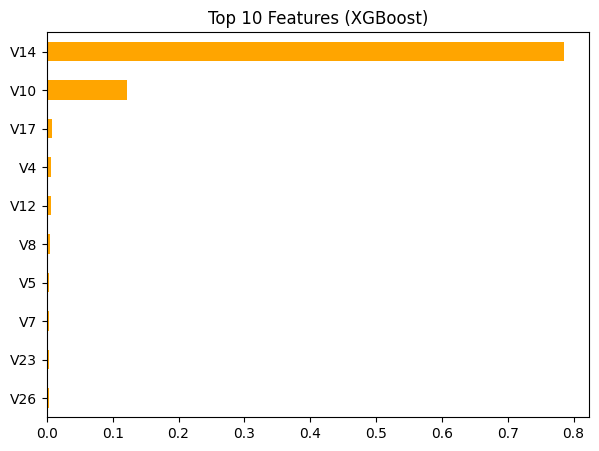

In [157]:
importance = pd.Series(models['XGBoost'].feature_importances_, index=X.columns)

plt.figure(figsize=(7, 5))
importance.sort_values().tail(10).plot(kind='barh', color='orange')
plt.title('Top 10 Features (XGBoost)')
plt.show()

The most important features are the same as the ones we saw in the correlation and boxplots (V14, V17, V12, V10...).

# How much does the bank lose?

- if a fraud is missed, the bank loses the amount of the transaction
- if a normal transaction is blocked (false alert), I consider it costs 5 €

In [158]:
def cost(y_true, y_pred, amount):
    missed = (y_true == 1) & (y_pred == 0)
    false_alert = (y_true == 0) & (y_pred == 1)
    return amount[missed].sum() + false_alert.sum() * 5

In [159]:
costs = {'No model': cost(y_test.values, np.zeros(len(y_test)), amount_test)}
for name in models:
    costs[name] = cost(y_test.values, predictions[name], amount_test)

costs = pd.Series(costs).round(0)
costs

No model               14766.0
Logistic Regression     8806.0
Decision Tree           5676.0
Random Forest           4335.0
XGBoost                 5673.0
LightGBM                7309.0
dtype: float64

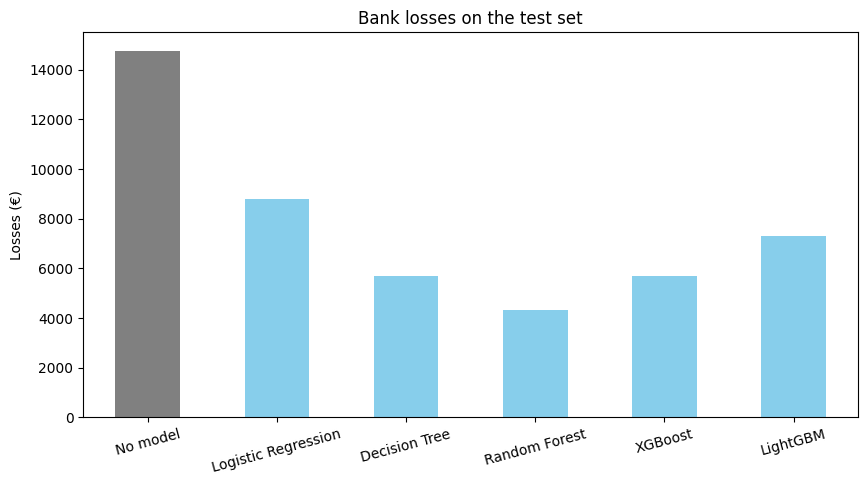

In [160]:
plt.figure(figsize=(10, 5))
costs.plot(kind='bar', color=['gray'] + ['skyblue'] * len(models), rot=15)
plt.ylabel('Losses (€)')
plt.title('Bank losses on the test set')
plt.show()

In [161]:
best = costs.drop('No model').idxmin()
print('Best model:', best)
print(f"Losses: {costs[best]:.0f} € instead of {costs['No model']:.0f} €")
print(f"Losses avoided: {(1 - costs[best] / costs['No model']) * 100:.1f} %")

Best model: Random Forest
Losses: 4335 € instead of 14766 €
Losses avoided: 70.6 %


# Conclusion

- The dataset is very imbalanced (0.17% of frauds), so accuracy is not a good metric: predicting always Non-Fraud already gives 99.8% accuracy. All the models have an accuracy around 99.9%, so it doesn't help to compare them.
- V14, V17, V12 and V10 are the most useful features to detect frauds (correlation, boxplots and feature importance all show it).
- **Random Forest** is the best model at the default threshold (0.5): it detects **72.6% of the frauds (69 out of 95)** with a precision of **97.2%** (F1 = 0.831).
- **XGBoost** has the best PR-AUC (0.809 vs 0.788 for Random Forest), so it ranks frauds slightly better, but at threshold 0.5 it catches fewer frauds.
- With the Random Forest, the bank loses **4 335 € instead of 14 766 €** without a model, so **70.6% of the losses are avoided**.
- Logistic Regression is the weakest "real" model (recall 0.589, cost 8 806 €). LightGBM gives a lot of false alerts here (precision 0.315), probably because its settings are not adapted to such imbalanced data.

**Next steps:** tune the hyperparameters, try class weights or SMOTE, and choose a better decision threshold than 0.5 (a lower threshold could catch more frauds, especially with XGBoost).